# Sherrerd Field Linear Reservoir Model

## Project Statement

This project develops a simple reservoir model to represent the rainfall–outflow response of the Sherrerd Field stormwater BMP.

The BMP is treated as an effective storage reservoir rather than explicitly modeling the turf, gravel layer, native soil, underdrain network, and outlet structure separately.

Rainfall adds water to storage, while water leaves the system through a simplified drainage relationship. The modeled outflow is compared with observed discharge from monitored storm events.

The objective is to determine whether a small number of effective parameters can reproduce the timing and magnitude of observed BMP outflow.

## Conceptual Model and Equations

The Sherrerd Field BMP is represented as a single effective storage reservoir.

Rainfall enters the reservoir and increases storage. Once storage exceeds an effective threshold, water is released as outflow.

The reservoir water balance is:

\[
\frac{dS}{dt} = P(t) - Q(t)
\]

where:

- \(S\) = effective BMP storage,
- \(P(t)\) = rainfall input rate,
- \(Q(t)\) = BMP outflow rate.

Outflow is represented using a threshold linear reservoir relationship:

\[
Q(t) = k \max(S - S_0, 0)
\]

where:

- \(k\) = reservoir drainage coefficient,
- \(S_0\) = effective storage threshold before outflow begins.

When \(S \leq S_0\), the model produces no outflow. When \(S > S_0\), discharge increases linearly with the amount of storage above the threshold.

This simplified formulation does not attempt to represent individual soil layers, gravel storage, pipes, or outlet structures explicitly. Instead, their combined behavior is represented through the effective parameters \(k\) and \(S_0\).

# Imports and Data Setup

The model uses a small set of Python libraries for numerical calculations, data handling, and plotting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#reading the google sheet that contains the raw data

sheet_id = "1MxK-rlqkJp05xgqTJxLkQGFdfYANmgrI"
gid = "967812734"

# URL to view the Google Sheet in your browser
view_url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={gid}"

# URL to read the sheet data into Python
csv_url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}"

print(view_url)

raw = pd.read_csv(csv_url)

raw.head()

https://docs.google.com/spreadsheets/d/1MxK-rlqkJp05xgqTJxLkQGFdfYANmgrI/edit#gid=967812734


,Date,Time,"Water Flow (M-WF-VNW 22148420:22356843-5),cfs,Shererd Field (1952 Stadium),Shererd Effluent Flow",Date.1,Time.1,"Rain (RXW-RGE 21286591:21509777-1),in,Soccer+Irr Well @ East Campus,rain gauge inches"
0,07/20/26,12:30:00,0.0,07/01/26,0:00:00,0.0
1,07/20/26,12:35:00,0.0,07/01/26,0:05:00,0.0
2,07/20/26,12:40:00,0.0,07/01/26,0:10:00,0.0
3,07/20/26,12:45:00,0.0,07/01/26,0:15:00,0.0
4,07/20/26,12:50:00,0.0,07/01/26,0:20:00,0.0


In [3]:
#changing the column names for simplicity

raw = raw.rename(columns={
    raw.columns[0]: "flow_date",
    raw.columns[1]: "flow_time",
    raw.columns[2]: "flow_cfs",

    raw.columns[3]: "rain_date",
    raw.columns[4]: "rain_time",
    raw.columns[5]: "rain_in"
})

raw.head()


,flow_date,flow_time,flow_cfs,rain_date,rain_time,rain_in
0,07/20/26,12:30:00,0.0,07/01/26,0:00:00,0.0
1,07/20/26,12:35:00,0.0,07/01/26,0:05:00,0.0
2,07/20/26,12:40:00,0.0,07/01/26,0:10:00,0.0
3,07/20/26,12:45:00,0.0,07/01/26,0:15:00,0.0
4,07/20/26,12:50:00,0.0,07/01/26,0:20:00,0.0


In [4]:
#combining date and time columns into one for simplicity

raw["flow_datetime"] = pd.to_datetime(
    raw["flow_date"].astype(str)
    + " "
    + raw["flow_time"].astype(str),
    errors="coerce"
)

raw["rain_datetime"] = pd.to_datetime(
    raw["rain_date"].astype(str)
    + " "
    + raw["rain_time"].astype(str),
    errors="coerce"
)


# Display the head to verify the new datetime columns
raw.head()

/tmp/ipykernel_16815/4244042038.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  raw["flow_datetime"] = pd.to_datetime(
/tmp/ipykernel_16815/4244042038.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  raw["rain_datetime"] = pd.to_datetime(


,flow_date,flow_time,flow_cfs,rain_date,rain_time,rain_in,flow_datetime,rain_datetime
0,07/20/26,12:30:00,0.0,07/01/26,0:00:00,0.0,2026-07-20 12:30:00,2026-07-01 00:00:00
1,07/20/26,12:35:00,0.0,07/01/26,0:05:00,0.0,2026-07-20 12:35:00,2026-07-01 00:05:00
2,07/20/26,12:40:00,0.0,07/01/26,0:10:00,0.0,2026-07-20 12:40:00,2026-07-01 00:10:00
3,07/20/26,12:45:00,0.0,07/01/26,0:15:00,0.0,2026-07-20 12:45:00,2026-07-01 00:15:00
4,07/20/26,12:50:00,0.0,07/01/26,0:20:00,0.0,2026-07-20 12:50:00,2026-07-01 00:20:00


In [5]:
flow = raw[
    ["flow_datetime", "flow_cfs"]
].dropna().copy()

rain = raw[
    ["rain_datetime", "rain_in"]
].dropna().copy()

#example new cells in the rain table
display(flow.head())
print("\n")
display(rain.head())

,flow_datetime,flow_cfs
0,2026-07-20 12:30:00,0.0
1,2026-07-20 12:35:00,0.0
2,2026-07-20 12:40:00,0.0
3,2026-07-20 12:45:00,0.0
4,2026-07-20 12:50:00,0.0


,rain_datetime,rain_in
0,2026-07-01 00:00:00,0.0
1,2026-07-01 00:05:00,0.0
2,2026-07-01 00:10:00,0.0
3,2026-07-01 00:15:00,0.0
4,2026-07-01 00:20:00,0.0


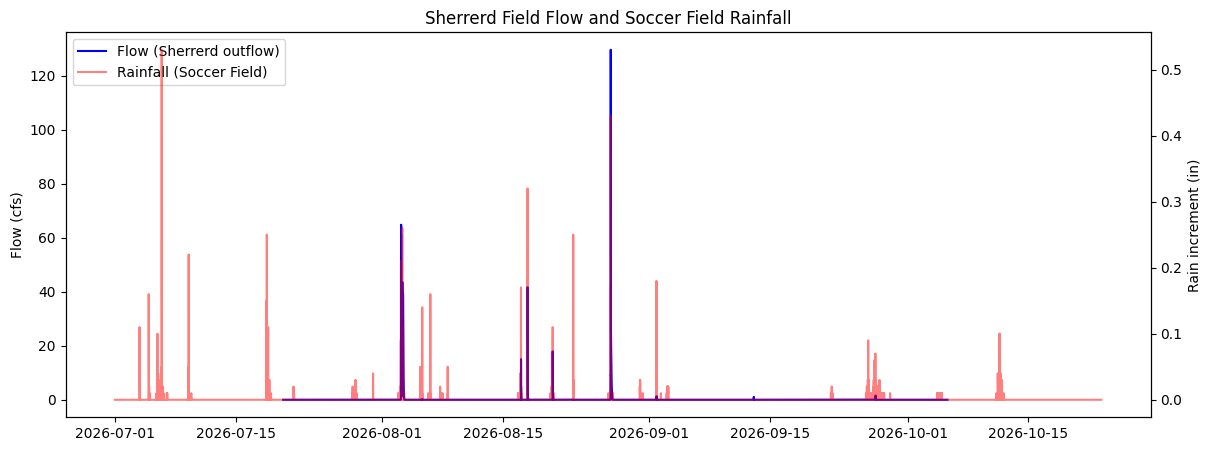

In [6]:
#plotting both the flow and rain information on the same graph during the date interval

fig, ax1 = plt.subplots(figsize=(14, 5))

line1, = ax1.plot(
    flow["flow_datetime"],
    flow["flow_cfs"],
    color="blue",
    label="Flow (Sherrerd outflow)"
)

ax1.set_ylabel("Flow (cfs)")

ax2 = ax1.twinx()

line2, = ax2.plot(
    rain["rain_datetime"],
    rain["rain_in"],
    alpha=0.5,
    color="red",
    label="Rainfall (Soccer Field)"
)

ax2.set_ylabel("Rain increment (in)")

# Combined legend for both axes
ax1.legend(handles=[line1, line2], loc="upper left")

plt.title("Sherrerd Field Flow and Soccer Field Rainfall")
plt.show()

# Choosing a sample interval for validating the model

In [7]:
# top 10 highest flow measurements
display(
    flow.nlargest(10, "flow_cfs")
)

#highest hourly increment for the rain
rain_hourly = (
    rain
    .set_index("rain_datetime")
    .resample("1h")["rain_in"]
    .sum()
    .reset_index()
)

rain_hourly.nlargest(10, "rain_in")

,flow_datetime,flow_cfs
10951,2026-08-27 13:05:00,129.6697
10952,2026-08-27 13:10:00,102.8367
10953,2026-08-27 13:15:00,73.6778
3945,2026-08-03 05:15:00,64.8442
3941,2026-08-03 04:55:00,61.0984
3942,2026-08-03 05:00:00,46.2113
10954,2026-08-27 13:20:00,46.1491
3986,2026-08-03 08:40:00,43.5405
8172,2026-08-17 21:30:00,41.6854
4008,2026-08-03 10:30:00,39.3562


,rain_datetime,rain_in
130,2026-07-06 10:00:00,1.32
1381,2026-08-27 13:00:00,0.95
796,2026-08-03 04:00:00,0.94
422,2026-07-18 14:00:00,0.85
1149,2026-08-17 21:00:00,0.78
800,2026-08-03 08:00:00,0.77
1380,2026-08-27 12:00:00,0.74
797,2026-08-03 05:00:00,0.60
2464,2026-10-11 16:00:00,0.60
1131,2026-08-17 03:00:00,0.56


In [8]:
start = "2026-08-02 00:00"
end   = "2026-08-04 00:00"

flow_event = flow[
    (flow["flow_datetime"] >= start)
    & (flow["flow_datetime"] <= end)
].copy()

rain_event = rain[
    (rain["rain_datetime"] >= start)
    & (rain["rain_datetime"] <= end)
].copy()

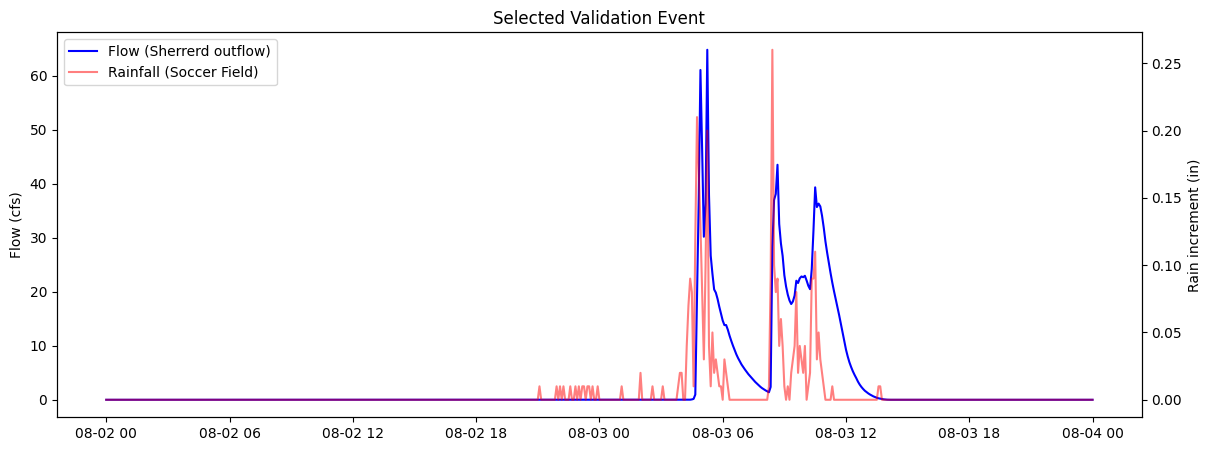

In [9]:
fig, ax1 = plt.subplots(figsize=(14, 5))

line1, = ax1.plot(
    flow_event["flow_datetime"],
    flow_event["flow_cfs"],
    color="blue",
    label="Flow (Sherrerd outflow)"
)

ax1.set_ylabel("Flow (cfs)")


ax2 = ax1.twinx()

line2, = ax2.plot(
    rain_event["rain_datetime"],
    rain_event["rain_in"],
    color="red",
    alpha=0.5,
    label="Rainfall (Soccer Field)"
)

ax2.set_ylabel("Rain increment (in)")

ax1.legend(
    handles=[line1, line2],
    loc="upper left"
)

plt.title("Selected Validation Event")

plt.show()

In [10]:
# Make sure both are sorted
flow_event = flow_event.sort_values("flow_datetime")
rain_event = rain_event.sort_values("rain_datetime")

#This takes the raw Soccer Field rainfall records and groups them into 5-minute bins.

rain_5min = (
    rain_event
    .set_index("rain_datetime")
    .resample("5min")["rain_in"]
    .sum()
    .reset_index()
)

#This converts the 5-minute rainfall depth to rainfall intensity.

rain_5min.head()

rain_5min["rain_in_hr"] = (
    rain_5min["rain_in"] * 12
)

#renaming the timestamps and combining

flow_event = flow_event.rename(
    columns={"flow_datetime": "time"}
)

rain_5min = rain_5min.rename(
    columns={"rain_datetime": "time"}
)

#For every Sherrerd flow measurement, find the nearest 5-minute Soccer rainfall interval, as long as it's within 3 minutes.

event = pd.merge_asof(
    flow_event.sort_values("time"),
    rain_5min.sort_values("time"),
    on="time",
    direction="nearest",
    tolerance=pd.Timedelta("3min")
)

event["rain_in_hr"] = (
    event["rain_in_hr"]
    .fillna(0)
)

#this converts actual time into -> 0 min after starting, 5 min after starting etc intervals

event["time_min"] = (
    event["time"] - event["time"].iloc[0]
).dt.total_seconds() / 60

calibration_data = event[
    ["time_min", "rain_in_hr", "flow_cfs"]
].copy()

calibration_data.head()

,time_min,rain_in_hr,flow_cfs
0,0.0,0.0,0.0
1,5.0,0.0,0.0
2,10.0,0.0,0.0
3,15.0,0.0,0.0
4,20.0,0.0,0.0


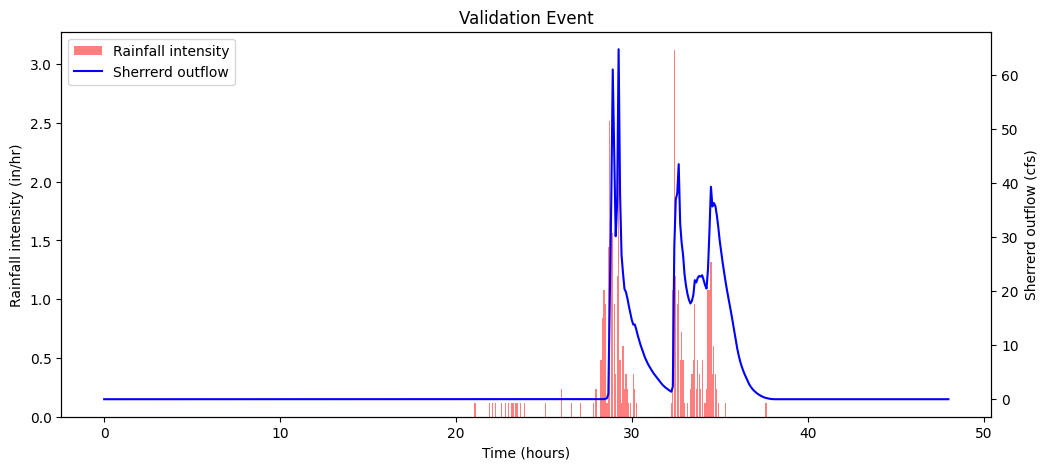

In [11]:
fig, ax1 = plt.subplots(figsize=(12, 5))

bars = ax1.bar(
    calibration_data["time_min"] / 60,
    calibration_data["rain_in_hr"],
    width=0.07,
    alpha=0.5,
    color="red",
    label="Rainfall intensity"
)

ax1.set_xlabel("Time (hours)")
ax1.set_ylabel("Rainfall intensity (in/hr)")

ax2 = ax1.twinx()

line, = ax2.plot(
    calibration_data["time_min"] / 60,
    calibration_data["flow_cfs"],
    color="blue",
    label="Sherrerd outflow"
)

ax2.set_ylabel("Sherrerd outflow (cfs)")

handles = [bars, line]
labels = [h.get_label() for h in handles]

ax1.legend(handles, labels, loc="upper left")

plt.title("Validation Event")
plt.show()

In [12]:
area_ft2 = 108000.0   # replace with Sherrerd contributing area
dt_hr = np.median(np.diff(calibration_data["time_min"])) / 60

total_rain_in = (
    calibration_data["rain_in_hr"] * dt_hr
).sum()

rain_volume_ft3 = (
    total_rain_in / 12
    * area_ft2
)

observed_volume_ft3 = (
    calibration_data["flow_cfs"]
    * dt_hr * 3600
).sum()

print(f"Total rainfall: {total_rain_in:.2f} in")
print(f"Rainfall volume: {rain_volume_ft3:,.0f} ft³")
print(f"Observed outflow volume: {observed_volume_ft3:,.0f} ft³")
print(
    "Observed / rainfall volume:",
    observed_volume_ft3 / rain_volume_ft3
)

Total rainfall: 3.41 in
Rainfall volume: 30,690 ft³
Observed outflow volume: 539,404 ft³
Observed / rainfall volume: 17.575877810361686


#Linear Reservoir Modeling

Now using simply set up to model

In [13]:
k = 0.5      # drainage coefficient [1/hr]
S0 = 5.0    # storage threshold [in]

In [14]:
def simulate_reservoir(data, k, S0):

    dt_hr = np.median(
        np.diff(data["time_min"])
    ) / 60

    storage = 0.0

    storage_series = []
    outflow_in_hr = []

    for rain in data["rain_in_hr"]:

        storage += rain * dt_hr

        q = k * max(
            storage - S0,
            0.0
        )

        outflow_depth = q * dt_hr

        available = max(
            storage - S0,
            0.0
        )

        outflow_depth = min(
            outflow_depth,
            available
        )

        storage -= outflow_depth

        storage_series.append(storage)

        outflow_in_hr.append(
            outflow_depth / dt_hr
        )

    return pd.DataFrame({
        "time_min": data["time_min"],
        "rain_in_hr": data["rain_in_hr"],
        "storage_in": storage_series,
        "modeled_outflow_in_hr": outflow_in_hr
    })

In [15]:
simulation = simulate_reservoir(
    calibration_data,
    k,
    S0
)

simulation.head()

,time_min,rain_in_hr,storage_in,modeled_outflow_in_hr
0,0.0,0.0,0.0,0.0
1,5.0,0.0,0.0,0.0
2,10.0,0.0,0.0,0.0
3,15.0,0.0,0.0,0.0
4,20.0,0.0,0.0,0.0


In [16]:
simulation["modeled_flow_cfs"] = (
    simulation["modeled_outflow_in_hr"]
    * area_ft2
    / 12
    / 3600
)

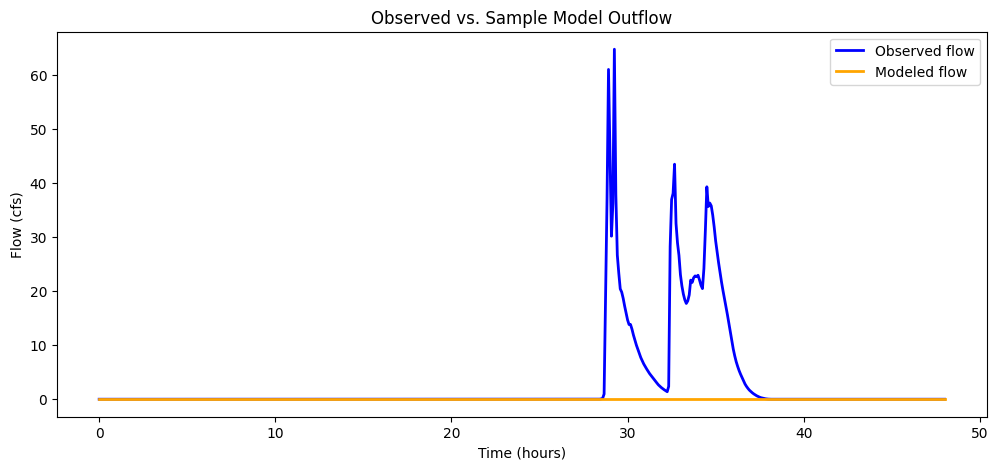

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    calibration_data["time_min"] / 60,
    calibration_data["flow_cfs"],
    label="Observed flow",
    color="blue",
    linewidth=2
)

ax.plot(
    simulation["time_min"] / 60,
    simulation["modeled_flow_cfs"],
    label="Modeled flow",
    color="orange",
    linewidth=2
)

ax.set_xlabel("Time (hours)")
ax.set_ylabel("Flow (cfs)")
ax.set_title("Observed vs. Sample Model Outflow")

ax.legend()

plt.show()

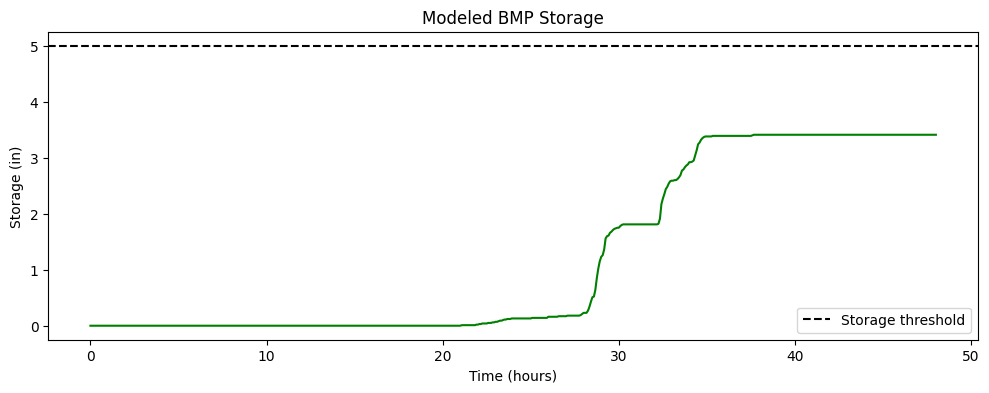

In [18]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    simulation["time_min"] / 60,
    simulation["storage_in"],
    color="green"
)

ax.axhline(
    S0,
    linestyle="--",
    color="black",
    label="Storage threshold"
)

ax.set_xlabel("Time (hours)")
ax.set_ylabel("Storage (in)")
ax.set_title("Modeled BMP Storage")

ax.legend()

plt.show()

## Calibration

The model parameters \(k\) and \(S_0\) are calibrated by testing many parameter combinations and selecting the pair that minimizes the root mean square error (RMSE) between observed and modeled outflow.

This grid-search approach is intentionally simple and transparent.

In [19]:
dt_hr = np.median(
    np.diff(calibration_data["time_min"])
) / 60

total_rain_in = (
    calibration_data["rain_in_hr"]
    * dt_hr
).sum()

print(f"Total event rainfall: {total_rain_in:.2f} in")

Total event rainfall: 3.41 in


In [20]:
k_values = np.linspace(
    0.05,
    2.0,
    40
)

S0_values = np.linspace(
    0,
    3,
    61
)

In [21]:
best_rmse = np.inf
best_k = None
best_S0 = None

for k_test in k_values:

    for S0_test in S0_values:

        sim = simulate_reservoir(
            calibration_data,
            k_test,
            S0_test
        )

        modeled_flow_cfs = (
            sim["modeled_outflow_in_hr"]
            * area_ft2
            / 3600
            / 12
        )

        observed_flow_cfs = (
            calibration_data["flow_cfs"]
            .to_numpy()
        )

        rmse = np.sqrt(
            np.mean(
                (
                    modeled_flow_cfs
                    - observed_flow_cfs
                ) ** 2
            )
        )

        if rmse < best_rmse:

            best_rmse = rmse
            best_k = k_test
            best_S0 = S0_test

In [22]:
print(f"Best k: {best_k:.3f} 1/hr")
print(f"Best S0: {best_S0:.1f} in")
print(f"Best RMSE: {best_rmse:.3f} cfs")

Best k: 2.000 1/hr
Best S0: 0.2 in
Best RMSE: 8.813 cfs


In [23]:
calibrated_simulation = simulate_reservoir(
    calibration_data,
    best_k,
    best_S0
)

calibrated_simulation["modeled_flow_cfs"] = (
    calibrated_simulation["modeled_outflow_in_hr"]
    * area_ft2
    / 3600
    / 12
)

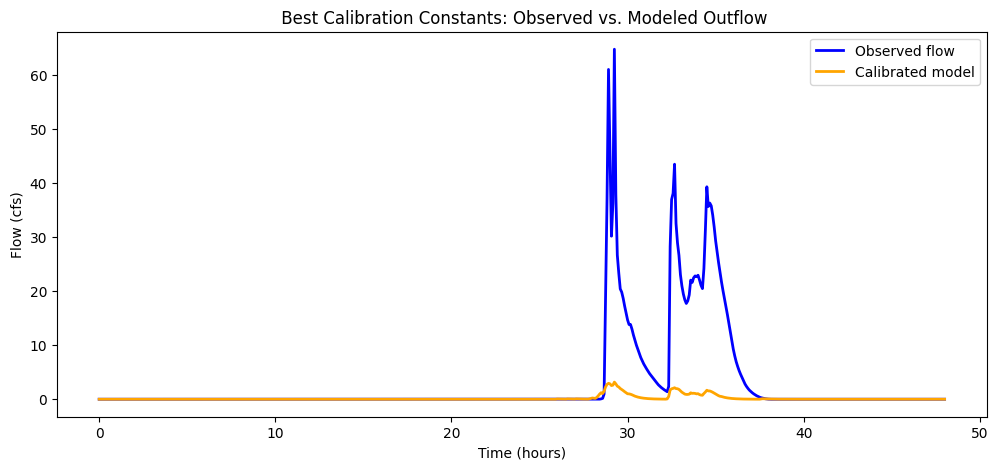

In [24]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    calibration_data["time_min"] / 60,
    calibration_data["flow_cfs"],
    label="Observed flow",
    color="blue",
    linewidth=2
)

ax.plot(
    calibrated_simulation["time_min"] / 60,
    calibrated_simulation["modeled_flow_cfs"],
    label="Calibrated model",
    color="orange",
    linewidth=2
)

ax.set_xlabel("Time (hours)")
ax.set_ylabel("Flow (cfs)")
ax.set_title(" Best Calibration Constants: Observed vs. Modeled Outflow")

ax.legend()

plt.show()